# Concentrated and distributed loading of an elastic cantilever

This example compares two ways of applying the same downward force. Does mesh refinement settle the displacement and elastic energy in both cases?

We use a **two-dimensional plane-stress continuum**, not a one-dimensional beam model. The rectangle is $\Omega=(0,4)\times(0,1)$, with unit thickness, $E=1$, $\nu=0.3$, and downward resultant $P=10^{-6}$. Lengths, modulus, and force are expressed in consistent nondimensional units. The left edge is fixed. There is no body force.

- **Point load:** apply $(0,-P)^T$ at $\boldsymbol{x}_P=(4,1/2)^T$.
- **Distributed load:** apply a smooth parabolic traction over the fixed segment $x=4$, $1/4\le y\le3/4$. Its resultant is also $(0,-P)^T$.

Both forces have the same moment about the clamp. The small load keeps the computed displacements modest on the meshes tested; it does not remove the point-load singularity. All computations run on one MPI process.


In [1]:
import os
import sys
from pathlib import Path

if sys.platform == "darwin":
    os.environ.setdefault("CC", "/usr/bin/clang")
    os.environ.setdefault("LDSHARED", "/usr/bin/clang -bundle -undefined dynamic_lookup")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.ticker import NullFormatter
import ufl
import dolfinx
from dolfinx import fem, mesh, plot
from dolfinx.fem import petsc
from mpi4py import MPI
from petsc4py import PETSc

plt.rcParams.update({"font.size": 13, "axes.titlesize": 14})
print("DOLFINx:", dolfinx.__version__)


DOLFINx: 0.11.0


## Geometry and the two loads

The arrows indicate load direction, not deformation. The distributed load has a fixed width $w=1/2$ on every mesh.


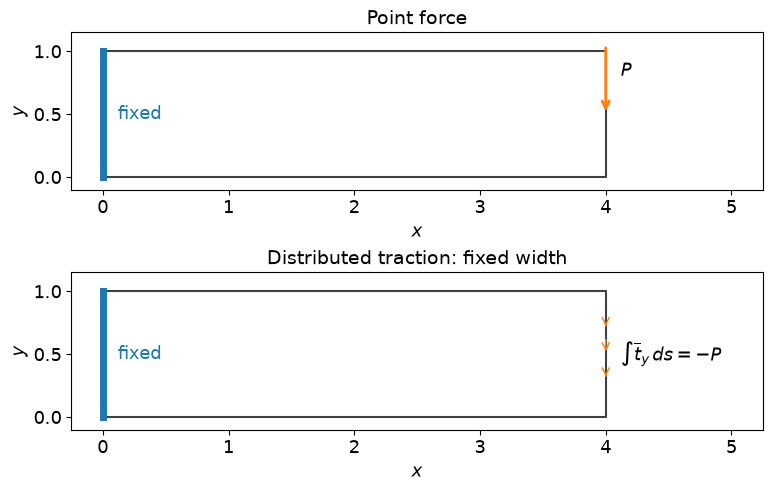

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4.8), layout="constrained")
for ax, title in zip(axes, ["Point force", "Distributed traction: fixed width"]):
    ax.plot([0, 4, 4, 0, 0], [0, 0, 1, 1, 0], color="0.25")
    ax.plot([0, 0], [0, 1], color="tab:blue", linewidth=5)
    ax.set(xlim=(-0.25, 5.25), ylim=(-0.1, 1.15),
           xlabel=r"$x$", ylabel=r"$y$", title=title, aspect="equal")
    ax.text(0.12, 0.5, "fixed", va="center", color="tab:blue")
axes[0].annotate("", xy=(4, 0.5), xytext=(4, 1.05),
                 arrowprops={"arrowstyle": "->", "color": "tab:orange", "lw": 2})
axes[0].text(4.12, 0.8, r"$P$")
for y in np.linspace(0.3, 0.7, 3):
    s = (y - 0.25) / 0.5
    axes[1].annotate("", xy=(4, y), xytext=(4, y + 0.14 * 4 * s * (1-s)),
                     arrowprops={"arrowstyle": "->", "color": "tab:orange"})
axes[1].text(4.12, 0.5, r"$\int\overline{t}_y\,ds=-P$", va="center")
plt.show()


## Variational forms and the finite element load vector

For plane stress,
$$
\boldsymbol{\varepsilon}(\boldsymbol{u})
=\tfrac12(\nabla\boldsymbol{u}+\nabla\boldsymbol{u}^{T}),\qquad
\boldsymbol{\sigma}(\boldsymbol{u})
=2\mu\boldsymbol{\varepsilon}(\boldsymbol{u})
+\lambda_{\mathrm{ps}}\operatorname{tr}(\boldsymbol{\varepsilon}(\boldsymbol{u}))\boldsymbol{I},
$$
where $\mu=E/[2(1+\nu)]$ and $\lambda_{\mathrm{ps}}=E\nu/(1-\nu^2)$. There is no body force, so $-\nabla\cdot\boldsymbol{\sigma}=\boldsymbol{0}$ in $\Omega$. The distributed-load case has zero traction on the upper and lower edges and on the unloaded part of the right edge. The point-load case has zero traction away from the force.
The discrete test and trial space consists of continuous vector-valued $P_1$ functions that vanish on $x=0$. The bilinear form is
$$
a_{\mathrm{el}}(\boldsymbol{u},\boldsymbol{v})
=\int_\Omega\boldsymbol{\sigma}(\boldsymbol{u}):
\boldsymbol{\varepsilon}(\boldsymbol{v})\,d\boldsymbol{x}.
$$

For the distributed load, set $s=(y-1/4)/w$ on the loaded segment $\Gamma_P$. Then
$$
\overline{\boldsymbol{t}}(y)
=\begin{bmatrix}0\\-6P\,s(1-s)/w\end{bmatrix},\qquad
\ell_{\mathrm{dist}}(\boldsymbol{v})
=\int_{\Gamma_P}\overline{\boldsymbol{t}}\cdot\boldsymbol{v}\,ds.
$$
The integral of its vertical component is $-6P\int_0^1s(1-s)\,ds=-P$.

For the point load, the **discrete** load functional is
$$
\ell_{\mathrm{point}}(\boldsymbol{v}_h)=-P\,v_{h,y}(\boldsymbol{x}_P).
$$
Since $\boldsymbol{x}_P$ is a node on every mesh, this means adding $-P$ to its vertical entry in the assembled load vector. It is not a traction spread over one mesh edge.

Point evaluation is defined for these continuous finite element functions, but it is not a bounded functional on the continuum $H^1$ space in two dimensions. Solving each finite element system therefore does not establish the existence of a finite-energy continuum solution for the ideal point force.


In [3]:
E = 1.0
nu = 0.3
P = 1.0e-6
width = 0.5
mu = E / (2 * (1 + nu))
lambda_ps = E * nu / (1 - nu**2)

def strain(u):
    return ufl.sym(ufl.grad(u))

def stress(u):
    return 2 * mu * strain(u) + lambda_ps * ufl.tr(strain(u)) * ufl.Identity(2)


## Assemble and solve

Use $4n$ subdivisions along the length and $n$ along the height. All refinement levels are nested, and $h=\sqrt{2}/n$.

DOLFINx stores this vector-valued $P_1$ space in blocks of two entries per node: horizontal, then vertical displacement. The code checks this layout before applying the point force. The PETSc lines assemble $\boldsymbol{K}$ and $\boldsymbol{F}$, impose zero displacement, and solve $\boldsymbol{K}\boldsymbol{U}=\boldsymbol{F}$ by direct LU factorization.

The function returns the solution and quantities needed for the comparison. Reactions use the original, unconstrained stiffness matrix.


In [4]:
def solve_cantilever(n, loading, domain=None, width=0.5):
    if domain is None:
        domain = mesh.create_rectangle(
            MPI.COMM_SELF, [np.array([0., 0.]), np.array([4., 1.])],
            [4*n, n], cell_type=mesh.CellType.triangle)
    V = fem.functionspace(domain, ("Lagrange", 1, (2,)))
    coordinates = V.tabulate_dof_coordinates()
    assert V.dofmap.index_map_bs == 2

    clamped_facets = mesh.locate_entities_boundary(
        domain, 1, lambda x: np.isclose(x[0], 0.0))
    clamped_dofs = fem.locate_dofs_topological(V, 1, clamped_facets)
    bc = fem.dirichletbc(np.zeros(2, dtype=PETSc.ScalarType), clamped_dofs, V)

    loaded_facets = mesh.locate_entities_boundary(
        domain, 1, lambda x: np.isclose(x[0], 4.0)
        & (x[1] >= 0.5-width/2 - 1e-10) & (x[1] <= 0.5+width/2 + 1e-10))
    tags = mesh.meshtags(domain, 1, loaded_facets,
                        np.ones(len(loaded_facets), dtype=np.int32))
    ds = ufl.Measure("ds", domain=domain, subdomain_data=tags,
                     metadata={"quadrature_degree": 4})
    x = ufl.SpatialCoordinate(domain)
    s = (x[1] - (0.5-width/2)) / width
    traction = ufl.as_vector((0., -6 * P / width * s * (1-s)))
    trial = ufl.TrialFunction(V)
    test = ufl.TestFunction(V)
    a = fem.form(ufl.inner(stress(trial), strain(test)) * ufl.dx)

    # This is also used to measure the same weighted end displacement in both cases.
    distributed_form = fem.form(ufl.dot(traction, test) * ds(1))
    F_distributed = petsc.assemble_vector(distributed_form)
    F_distributed.ghostUpdate(addv=PETSc.InsertMode.ADD, mode=PETSc.ScatterMode.REVERSE)
    F = F_distributed.copy()
    point_nodes = np.flatnonzero(np.isclose(coordinates[:, 0], 4.)
                                & np.isclose(coordinates[:, 1], 0.5))
    assert len(point_nodes) == 1
    point_node = point_nodes[0]
    if loading == "point":
        F.array[:] = 0
        F.array[2*point_node + 1] = -P
    elif loading != "distributed":
        raise ValueError("loading must be 'point' or 'distributed'")

    # Check resultant and moment of the assembled nodal forces before imposing BCs.
    nodal_forces = F.array.reshape(-1, 2)
    resultant = nodal_forces.sum(axis=0)
    moment = np.sum(coordinates[:, 0] * nodal_forces[:, 1]
                    - coordinates[:, 1] * nodal_forces[:, 0])
    K = petsc.assemble_matrix(a, bcs=[bc])
    K.assemble()
    petsc.set_bc(F, [bc])
    u_h = fem.Function(V)
    solver = PETSc.KSP().create(domain.comm)
    solver.setOperators(K)
    solver.setType("preonly")
    solver.getPC().setType("lu")
    solver.solve(F, u_h.x.petsc_vec)
    u_h.x.scatter_forward()
    assert solver.getConvergedReason() > 0

    compliance = F.dot(u_h.x.petsc_vec).real
    energy_squared = fem.assemble_scalar(fem.form(
        ufl.inner(stress(u_h), strain(u_h)) * ufl.dx)).real
    K_original = petsc.assemble_matrix(a)
    K_original.assemble()
    reactions = F.duplicate()
    K_original.mult(u_h.x.petsc_vec, reactions)
    reactions.axpy(-1, F)
    left_nodes = np.flatnonzero(np.isclose(coordinates[:, 0], 0.))
    reaction_y = reactions.array[2*left_nodes + 1].sum().real

    displacement = u_h.x.array.real.reshape(-1, 2)
    probe_nodes = np.flatnonzero(np.isclose(coordinates[:, 0], 3.)
                                & np.isclose(coordinates[:, 1], 0.5))
    assert len(probe_nodes) == 1
    midpoint_down = -displacement[point_node, 1]
    probe_down = -displacement[probe_nodes[0], 1]
    average_down = F_distributed.dot(u_h.x.petsc_vec).real / P

    # P1 displacement gives constant strain-energy density on each triangle.
    W = fem.functionspace(domain, ("DG", 0))
    density = fem.Function(W)
    density.interpolate(fem.Expression(
        0.5 * ufl.inner(stress(u_h), strain(u_h)), W.element.interpolation_points))
    count = domain.topology.index_map(2).size_local
    values = np.array([density.x.array[W.dofmap.cell_dofs(e)[0]].real
                       for e in range(count)])
    centers = mesh.compute_midpoints(domain, 2, np.arange(count, dtype=np.int32))
    near_load = np.linalg.norm(centers[:, :2] - [4., 0.5], axis=1) < 0.25
    peak_near_load = values[near_load].max()
    # W >= mu * (epsilon:epsilon) bounds the strain magnitude on these meshes.
    assert np.sqrt(values.max() / mu) < 0.05

    assert np.allclose(resultant, [0., -P], rtol=1e-10, atol=1e-12)
    assert np.isclose(moment, -4*P, rtol=1e-10)
    assert np.isclose(reaction_y, P, rtol=1e-7)
    assert np.isclose(compliance, energy_squared, rtol=1e-8)
    assert np.max(np.abs(displacement[left_nodes])) < 1e-12
    # The largest triangle edge gives h, including on nonuniform meshes.
    element_nodes = domain.geometry.x[domain.geometry.dofmap]
    h = 0.0
    for a, b in [(0, 1), (1, 2), (2, 0)]:
        h = max(h, np.linalg.norm(element_nodes[:, a] - element_nodes[:, b], axis=1).max())
    result = {
        "n": n, "h": h, "DOFs": len(u_h.x.array),
        "compliance/P^2": compliance/P**2,
        "midpoint displacement/P": midpoint_down/P,
        "weighted end displacement/P": average_down/P,
        "probe displacement/P": probe_down/P,
        "peak near-load density/P^2": peak_near_load/P**2,
        "reaction/P": reaction_y/P,
        "energy identity relative difference": abs(compliance-energy_squared)/energy_squared,
    }
    solver.destroy()
    K.destroy()
    K_original.destroy()
    F.destroy()
    F_distributed.destroy()
    reactions.destroy()
    return result, domain, u_h, values


## Run the comparison

The distributed segment is resolved on every mesh. We divide displacements by $P$ and energy quantities by $P^2$ so the results do not depend on the chosen load magnitude in this linear model.

The **compliance** is $C_h=\ell(\boldsymbol{u}_h)=a_{\mathrm{el}}(\boldsymbol{u}_h,\boldsymbol{u}_h)$; the stored elastic energy is $C_h/2$. In the point case, $C_h/P$ is the downward displacement at the load point. In the distributed case it is a traction-weighted average displacement, not the midpoint displacement. Both are listed separately.


In [5]:
n_values = [8, 16, 32, 64, 128]
point_rows = []
distributed_rows = []
for n in n_values:
    point_result, point_domain, point_u, point_density = solve_cantilever(n, "point")
    distributed_result, distributed_domain, distributed_u, distributed_density = solve_cantilever(n, "distributed")
    point_rows.append(point_result)
    distributed_rows.append(distributed_result)
    print(f"n={n:3d}, DOFs={point_result['DOFs']:6d}: "
          f"C_point/P^2={point_result['compliance/P^2']:.6f}, "
          f"C_distributed/P^2={distributed_result['compliance/P^2']:.6f}")

point_table = pd.DataFrame(point_rows)
distributed_table = pd.DataFrame(distributed_rows)
display(point_table.round(6))
display(distributed_table.round(6))


/var/folders/tt/zt64sf2n4kgfkx71d8pf39440000gn/T/ipykernel_44746/892400102.py:100: DeprecationWarning: dofmap is deprecated. Use dofmaps[0] instead.
  element_nodes = domain.geometry.x[domain.geometry.dofmap]


n=  8, DOFs=   594: C_point/P^2=253.867153, C_distributed/P^2=253.327009
n= 16, DOFs=  2210: C_point/P^2=264.482765, C_distributed/P^2=263.599760


n= 32, DOFs=  8514: C_point/P^2=267.677710, C_distributed/P^2=266.390186


n= 64, DOFs= 33410: C_point/P^2=268.846401, C_distributed/P^2=267.128501


n=128, DOFs=132354: C_point/P^2=269.481488, C_distributed/P^2=267.325211


,n,h,DOFs,compliance/P^2,midpoint displacement/P,weighted end displacement/P,probe displacement/P,peak near-load density/P^2,reaction/P,energy identity relative difference
0,8,0.176777,594,253.867153,253.867153,253.427948,161.301318,21.606312,1.0,0.0
1,16,0.088388,2210,264.482765,264.482765,263.719886,167.839616,85.801052,1.0,0.0
2,32,0.044194,8514,267.677710,267.677710,266.520380,169.621291,343.231573,1.0,0.0
3,64,0.022097,33410,268.846401,268.846401,267.261501,170.095839,1373.300867,1.0,0.0
4,128,0.011049,132354,269.481488,269.481488,267.458859,170.223625,5493.735102,1.0,0.0


,n,h,DOFs,compliance/P^2,midpoint displacement/P,weighted end displacement/P,probe displacement/P,peak near-load density/P^2,reaction/P,energy identity relative difference
0,8,0.176777,594,253.327009,253.427948,253.327009,161.301853,5.025947,1.0,0.0
1,16,0.088388,2210,263.599760,263.719886,263.599760,167.839916,8.000549,1.0,0.0
2,32,0.044194,8514,266.390186,266.520380,266.390186,169.621537,9.638808,1.0,0.0
3,64,0.022097,33410,267.128501,267.261501,267.128501,170.096072,10.526209,1.0,0.0
4,128,0.011049,132354,267.325211,267.458859,267.325211,170.223855,11.082011,1.0,0.0


## Does the sequence settle in energy?

For nested spaces, with the **same** load functional on both meshes, Galerkin orthogonality and symmetry give
$$
a_{\mathrm{el}}(\boldsymbol{u}_{h/2},\boldsymbol{u}_h)
=\ell(\boldsymbol{u}_h)
=a_{\mathrm{el}}(\boldsymbol{u}_h,\boldsymbol{u}_h)=C_h.
$$
Expanding the square therefore gives
$$
\|\boldsymbol{u}_{h/2}-\boldsymbol{u}_h\|_{a_{\mathrm{el}}}^2
=C_{h/2}-C_h.
$$
This identity uses only the discrete equations. It holds for both load vectors here; it does **not** assert the existence of a finite-energy continuum solution for the point force.

We plot this successive-mesh difference, not a true error. A sequence converging in energy must have these differences tend to zero. The converse does not follow from this check alone. For example, increments that merely become small need not establish convergence.


,fine n,point: successive energy difference/P,distributed: successive energy difference/P,point: compliance increment/P^2,distributed: compliance increment/P^2
0,16,3.258161,3.205113,10.615612,10.272751
1,32,1.787441,1.670457,3.194944,2.790427
2,64,1.081060,0.859252,1.168691,0.738315
3,128,0.796923,0.443520,0.635087,0.196710


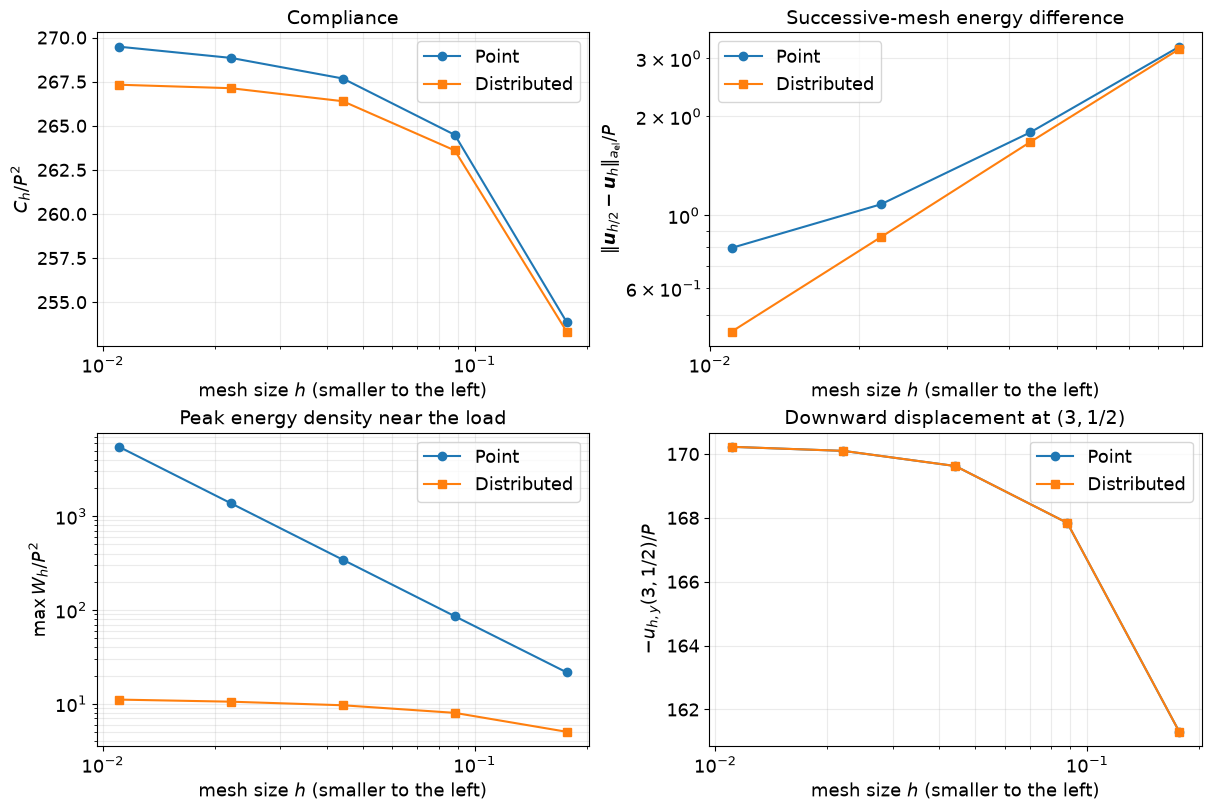

In [6]:
point_C = point_table["compliance/P^2"].to_numpy()
distributed_C = distributed_table["compliance/P^2"].to_numpy()
assert np.all(np.diff(point_C) > 0)
assert np.all(np.diff(distributed_C) > 0)
point_changes = np.sqrt(np.diff(point_C))
distributed_changes = np.sqrt(np.diff(distributed_C))
display(pd.DataFrame({
    "fine n": n_values[1:],
    "point: successive energy difference/P": point_changes,
    "distributed: successive energy difference/P": distributed_changes,
    "point: compliance increment/P^2": np.diff(point_C),
    "distributed: compliance increment/P^2": np.diff(distributed_C),
}).round(6))

fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
for table, label, marker in [(point_table, "Point", "o"),
                              (distributed_table, "Distributed", "s")]:
    axes[0, 0].semilogx(table["h"], table["compliance/P^2"], marker+"-", label=label)
    axes[1, 0].loglog(table["h"], table["peak near-load density/P^2"], marker+"-", label=label)
    axes[1, 1].semilogx(table["h"], table["probe displacement/P"], marker+"-", label=label)
fine_h = point_table["h"].to_numpy()[1:]
axes[0, 1].loglog(fine_h, point_changes, "o-", label="Point")
axes[0, 1].loglog(fine_h, distributed_changes, "s-", label="Distributed")
axes[0, 0].set(title="Compliance", ylabel=r"$C_h/P^2$")
axes[0, 1].set(title="Successive-mesh energy difference",
               ylabel=r"$\|\boldsymbol{u}_{h/2}-\boldsymbol{u}_h\|_{a_{\mathrm{el}}}/P$")
axes[1, 0].set(title="Peak energy density near the load",
               ylabel=r"$\max W_h/P^2$")
axes[1, 1].set(title=r"Downward displacement at $(3,1/2)$",
               ylabel=r"$-u_{h,y}(3,1/2)/P$")
for ax in axes.flat:
    ax.set_xlabel(r"mesh size $h$ (smaller to the left)")
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.grid(True, which="both", alpha=0.25)
    ax.legend()
plt.show()


## Where does the energy concentrate?

These plots use the same color scale and the **undeformed** geometry. The first column shows the whole cantilever. The second enlarges the region around the force. Color is $\log_{10}(W_h/P^2)$, with $W_h=\tfrac12\boldsymbol{\sigma}_h:\boldsymbol{\varepsilon}_h$.

The peak is measured only within distance $1/4$ of the load point. This avoids confusing the load singularity with possible singularities at the clamped corners. Peak density alone is not a convergence test.


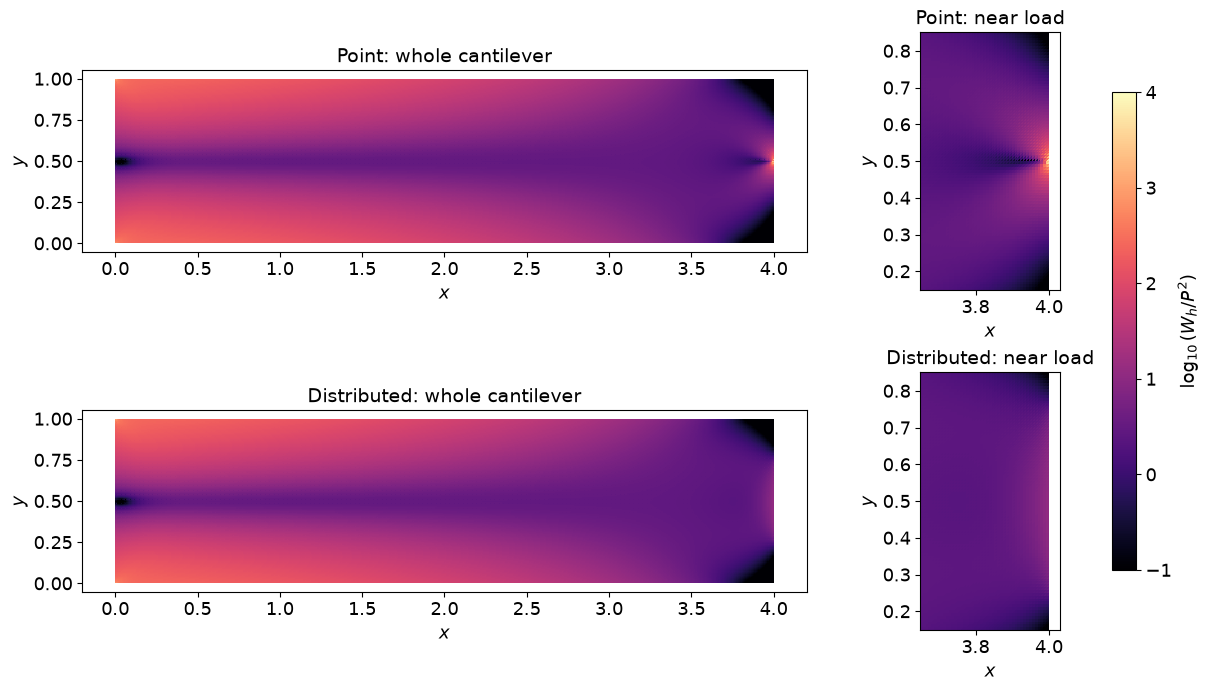

In [7]:
def draw_density(ax, domain, values, lower, upper, zoom=False):
    cells, _, coordinates = plot.vtk_mesh(domain)
    triangles = mtri.Triangulation(coordinates[:, 0], coordinates[:, 1],
                                  cells.reshape(-1, 4)[:, 1:])
    colors = np.log10(np.maximum(values/P**2, 1e-12))
    image = ax.tripcolor(triangles, facecolors=colors, shading="flat",
                         cmap="magma", vmin=lower, vmax=upper)
    if zoom:
        ax.set_xlim(3.65, 4.03)
        ax.set_ylim(0.15, 0.85)
    ax.set(xlabel=r"$x$", ylabel=r"$y$", aspect="equal")
    return image

logs = np.log10(np.maximum(np.concatenate([point_density, distributed_density])/P**2, 1e-12))
lower = np.floor(np.percentile(logs, 2))
upper = np.ceil(logs.max())
fig, axes = plt.subplots(2, 2, figsize=(12, 6.8), layout="constrained",
                          gridspec_kw={"width_ratios": [3, 1]})
for row, domain, values, label in [
        (0, point_domain, point_density, "Point"),
        (1, distributed_domain, distributed_density, "Distributed")]:
    draw_density(axes[row, 0], domain, values, lower, upper)
    image = draw_density(axes[row, 1], domain, values, lower, upper, zoom=True)
    axes[row, 0].set_title(label + ": whole cantilever")
    axes[row, 1].set_title(label + ": near load")
fig.colorbar(image, ax=axes, label=r"$\log_{10}(W_h/P^2)$", shrink=0.8)
plt.show()


## Separate bending error from the load singularity

On coarse meshes, both models have substantial bending discretization error. Now keep most of the mesh fixed and repeatedly refine a shrinking neighborhood of the load point. This is **prescribed local refinement**, not residual-based adaptive marking.

Start with $n=16$. At step $m$, mark triangles whose centers lie within radius $0.3\,2^{-m}$ of $\boldsymbol{x}_P$, then refine their edges. Mesh conformity also refines some neighboring triangles. The traction width stays fixed at $1/2$.

The same nested-space energy identity still applies. For the distributed case, this study only tests sensitivity to refinement near the load; it does not remove the remaining approximation error elsewhere in the cantilever.


/var/folders/tt/zt64sf2n4kgfkx71d8pf39440000gn/T/ipykernel_44746/892400102.py:100: DeprecationWarning: dofmap is deprecated. Use dofmaps[0] instead.
  element_nodes = domain.geometry.x[domain.geometry.dofmap]


,cycle,DOFs,point C/P^2,distributed C/P^2,point energy difference/P,distributed energy difference/P
0,0,2210,264.482765,263.599760,NaN,NaN
1,1,2476,264.945060,263.623443,0.679923,0.153893
2,2,2738,265.380093,263.626096,0.659570,0.051510
3,3,3000,265.816256,263.626276,0.660427,0.013422
4,4,3262,266.252657,263.626289,0.660606,0.003619
5,5,3524,266.689108,263.626290,0.660644,0.000969
6,6,3786,267.125569,263.626290,0.660652,0.000247


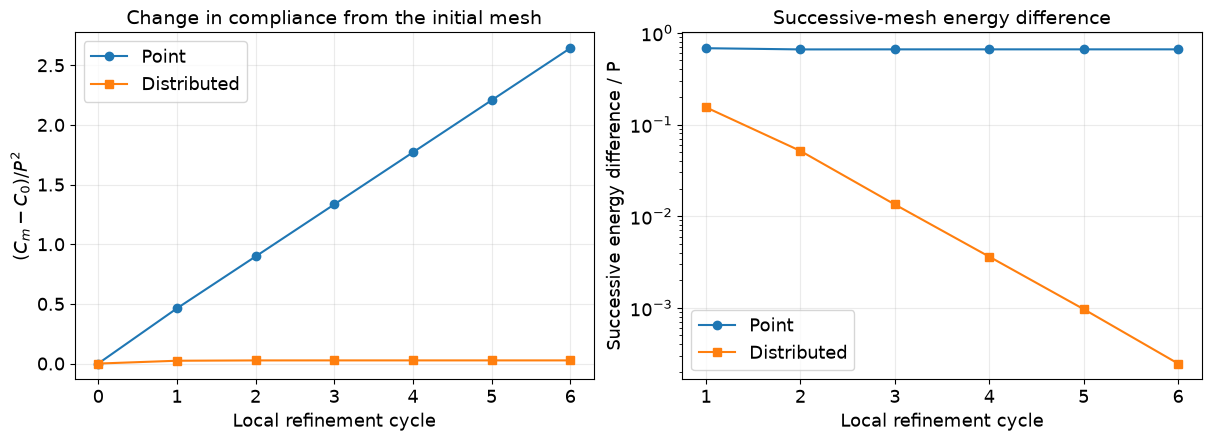

In [8]:
local_domain = mesh.create_rectangle(
    MPI.COMM_SELF, [np.array([0., 0.]), np.array([4., 1.])],
    [64, 16], cell_type=mesh.CellType.triangle)
local_point = []
local_distributed = []
local_dofs = []
local_meshes = []

for cycle in range(7):
    rp, _, _, _ = solve_cantilever(16, "point", local_domain)
    rd, _, _, _ = solve_cantilever(16, "distributed", local_domain)
    local_point.append(rp["compliance/P^2"])
    local_distributed.append(rd["compliance/P^2"])
    local_dofs.append(rp["DOFs"])
    local_meshes.append(local_domain)
    if cycle < 6:
        count = local_domain.topology.index_map(2).size_local
        elements = np.arange(count, dtype=np.int32)
        centers = mesh.compute_midpoints(local_domain, 2, elements)
        distance = np.linalg.norm(centers[:, :2] - [4., 0.5], axis=1)
        marked = elements[distance < 0.3 * 0.5**cycle]
        assert len(marked) > 0
        local_domain.topology.create_entities(1)
        local_domain.topology.create_connectivity(2, 1)
        edges = mesh.compute_incident_entities(local_domain.topology, marked, 2, 1)
        local_domain, _, _ = mesh.refine(local_domain, edges)

point_increments = np.diff(local_point)
distributed_increments = np.diff(local_distributed)
assert np.all(point_increments > 0)
assert np.all(distributed_increments > 0)
display(pd.DataFrame({
    "cycle": range(7), "DOFs": local_dofs,
    "point C/P^2": local_point,
    "distributed C/P^2": local_distributed,
    "point energy difference/P": [np.nan] + list(np.sqrt(point_increments)),
    "distributed energy difference/P": [np.nan] + list(np.sqrt(distributed_increments)),
}).round(6))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout="constrained")
axes[0].plot(range(7), np.array(local_point) - local_point[0], "o-", label="Point")
axes[0].plot(range(7), np.array(local_distributed) - local_distributed[0], "s-", label="Distributed")
axes[0].set(xlabel="Local refinement cycle", ylabel=r"$(C_m-C_0)/P^2$",
            title="Change in compliance from the initial mesh")
axes[1].semilogy(range(1, 7), np.sqrt(point_increments), "o-", label="Point")
axes[1].semilogy(range(1, 7), np.sqrt(distributed_increments),
                 "s-", label="Distributed")
axes[1].set(xlabel="Local refinement cycle", ylabel="Successive energy difference / P",
            title="Successive-mesh energy difference")
for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.25)
plt.show()


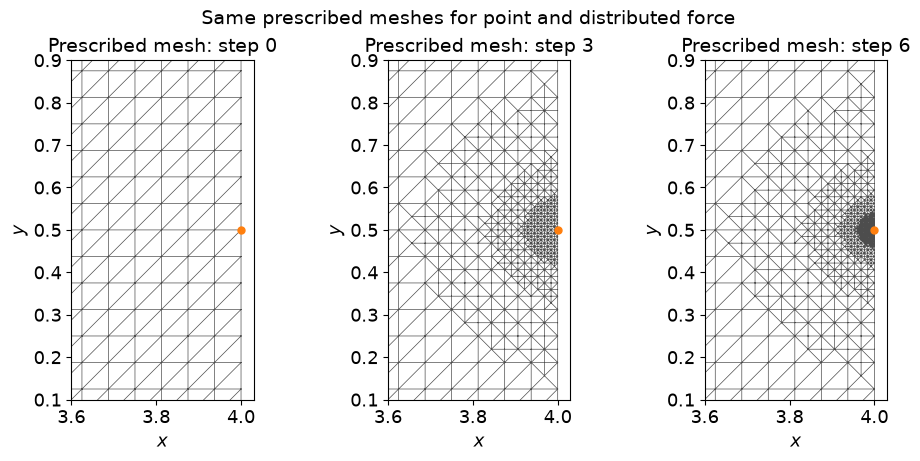

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(9.5, 4.5), layout="constrained")
for ax, cycle in zip(axes, [0, 3, 6]):
    cells, _, coordinates = plot.vtk_mesh(local_meshes[cycle])
    triangles = mtri.Triangulation(coordinates[:, 0], coordinates[:, 1],
                                  cells.reshape(-1, 4)[:, 1:])
    ax.triplot(triangles, color="0.3", linewidth=0.5)
    ax.plot(4., 0.5, "o", color="tab:orange", markersize=5)
    ax.set(xlim=(3.6, 4.03), ylim=(0.1, 0.9), aspect="equal",
           xlabel=r"$x$", ylabel=r"$y$", title=f"Prescribed mesh: step {cycle}")
fig.suptitle("Same prescribed meshes for point and distributed force", fontsize=14)
plt.show()


## Estimator-driven refinement for distributed loading

The preceding point-force experiment prescribed where refinement occurred. It did not use an estimator. Now let the **elasticity residual indicators** select the elements, with distributed widths $w=1/2$ and $w=1/4$.

For constant material and $P_1$ displacement, the element stress is constant and the body force is zero. Thus $\boldsymbol r_e=\boldsymbol 0$. The remaining residuals are
$$
\boldsymbol j_{\mathcal F}
=-\bigl(\boldsymbol\sigma_h^+\boldsymbol n^+
       +\boldsymbol\sigma_h^-\boldsymbol n^-\bigr)
\quad\text{on interior facets},\qquad
\boldsymbol j_{\mathcal F}
=\overline{\boldsymbol t}-\boldsymbol\sigma_h\boldsymbol n
\quad\text{on Neumann facets}.
$$
Zero prescribed traction on the top, bottom, and unloaded end facets still gives a boundary residual $-\boldsymbol\sigma_h\boldsymbol n$; these facets must not be omitted. There is no Neumann residual on the clamped edge.

For $E=1$, use the Chapter 8 vector-residual indicator
$$
\eta_e^2=
\frac12\sum_{\substack{\mathcal F\subset\partial\mathcal K_e\\
                        \mathcal F\ {\rm interior}}}
h_{\mathcal F}\int_{\mathcal F}\boldsymbol j_{\mathcal F}\cdot\boldsymbol j_{\mathcal F}\,ds
+\sum_{\substack{\mathcal F\subset\partial\mathcal K_e\\
                 \mathcal F\ {\rm Neumann}}}
h_{\mathcal F}\int_{\mathcal F}\boldsymbol j_{\mathcal F}\cdot\boldsymbol j_{\mathcal F}\,ds.
$$
Here $h_{\mathcal F}$ is edge length. This indicator is not an exact energy error; the reliability constant is not computed. It is **not evaluated for the ideal point force**.

The DG0 assembly below allocates one entry per element, just as in the Gaussian notebook. No discontinuous Galerkin PDE method is being used.


In [10]:
def estimate_elasticity(domain, u_h, width):
    """Return squared interior and Neumann contributions in element order."""
    domain.topology.create_connectivity(1, 2)
    W = fem.functionspace(domain, ("DG", 0))
    z = ufl.TestFunction(W)
    normal = ufl.FacetNormal(domain)
    h_F = ufl.avg(ufl.FacetArea(domain))
    sigma_h = stress(u_h)

    # Both sides of an interior facet receive half of its squared contribution.
    jump = -ufl.jump(sigma_h, normal)
    interior_form = (
        0.5*h_F*ufl.dot(jump, jump)*z("+")*ufl.dS
        + 0.5*h_F*ufl.dot(jump, jump)*z("-")*ufl.dS
    )

    # Tag the loaded segment 1 and all other Neumann facets 2.
    exterior = mesh.exterior_facet_indices(domain.topology)
    clamped = mesh.locate_entities_boundary(
        domain, 1, lambda x: np.isclose(x[0], 0.))
    loaded = mesh.locate_entities_boundary(
        domain, 1, lambda x: np.isclose(x[0], 4.)
        & (x[1] >= 0.5-width/2-1e-10) & (x[1] <= 0.5+width/2+1e-10))
    neumann = np.setdiff1d(exterior, clamped)
    tags = np.full(len(neumann), 2, dtype=np.int32)
    tags[np.isin(neumann, loaded)] = 1
    facet_tags = mesh.meshtags(domain, 1, neumann, tags)
    ds = ufl.Measure("ds", domain=domain, subdomain_data=facet_tags,
                     metadata={"quadrature_degree": 4})
    x = ufl.SpatialCoordinate(domain)
    s = (x[1] - (0.5-width/2)) / width
    traction = ufl.as_vector((0., -6*P/width*s*(1-s)))
    j_loaded = traction - ufl.dot(sigma_h, normal)
    j_free = -ufl.dot(sigma_h, normal)
    boundary_form = (
        ufl.FacetArea(domain)*ufl.dot(j_loaded, j_loaded)*z*ds(1)
        + ufl.FacetArea(domain)*ufl.dot(j_free, j_free)*z*ds(2)
    )
    interior_vector = fem.assemble_vector(fem.form(interior_form))
    boundary_vector = fem.assemble_vector(fem.form(boundary_form))
    count = domain.topology.index_map(2).size_local
    interior_part = np.zeros(count)
    boundary_part = np.zeros(count)
    for e in range(count):
        dof = W.dofmap.cell_dofs(e)[0]
        interior_part[e] = interior_vector.array[dof].real
        boundary_part[e] = boundary_vector.array[dof].real
    return interior_part, boundary_part


In [11]:
def mark_elements(squared_indicators, theta=0.5):
    order = np.argsort(squared_indicators)[::-1]
    marked = []
    selected_sum = 0.
    target = theta * squared_indicators.sum()
    for e in order:
        marked.append(e)
        selected_sum += squared_indicators[e]
        if selected_sum >= target:
            break
    return np.array(marked, dtype=np.int32)

def refine_marked_elements(domain, marked):
    domain.topology.create_entities(1)
    domain.topology.create_connectivity(2, 1)
    edges = mesh.compute_incident_entities(domain.topology, marked, 2, 1)
    refined, _, _ = mesh.refine(domain, edges)
    return refined


### Plotting the selection

The three rows show the indicator values, marked elements, and actual mesh returned by refinement. The thick black edge is clamped; the orange segment carries the distributed load. Each figure has its own indicator color scale, so compare the numerical colorbar values across cycles. Large residuals need not occur only where the load is applied.


In [12]:
def draw_elastic_refinement(domain, squared_indicators, marked, refined, title, width=0.5):
    cells, _, coordinates = plot.vtk_mesh(domain)
    triangles = mtri.Triangulation(
        coordinates[:, 0], coordinates[:, 1], cells.reshape(-1, 4)[:, 1:])
    fig, panels = plt.subplots(3, 2, figsize=(8, 7.2), layout="constrained",
                                gridspec_kw={"width_ratios": [30, 1]})
    axes = panels[:, 0]
    image = axes[0].tripcolor(triangles, facecolors=np.sqrt(squared_indicators)/P,
                              cmap="magma", shading="flat")
    axes[0].triplot(triangles, color="0.3", linewidth=0.25, alpha=0.5)
    fig.colorbar(image, cax=panels[0, 1], label=r"$\eta_e/P$")
    for ax in panels[1:, 1]:
        ax.axis("off")
    selected = np.zeros(len(squared_indicators))
    selected[marked] = 1.
    axes[1].tripcolor(triangles, facecolors=selected, cmap="Blues", vmin=0, vmax=1.5)
    axes[1].triplot(triangles, color="0.3", linewidth=0.3)
    cells_new, _, coordinates_new = plot.vtk_mesh(refined)
    new_triangles = mtri.Triangulation(
        coordinates_new[:, 0], coordinates_new[:, 1], cells_new.reshape(-1, 4)[:, 1:])
    axes[2].triplot(new_triangles, color="0.3", linewidth=0.3)
    for ax, heading in zip(axes, ["Indicators on current mesh",
                                  f"Marked elements (blue): {len(marked)}",
                                  "Conforming mesh after refinement"]):
        ax.set(title=heading, xlabel=r"$x_1$", ylabel=r"$x_2$", aspect="equal",
               xlim=(0, 4), ylim=(0, 1))
    for ax in axes:
        ax.plot([0, 0], [0, 1], color="black", linewidth=3)
        ax.plot([4, 4], [0.5-width/2, 0.5+width/2], color="tab:orange", linewidth=3)
    fig.suptitle(title, fontsize=15)
    return fig


### Run the adaptive loop

For each fixed width, start with $32\times8$ rectangles split into triangles. Use $\theta=0.5$, seven solves, and six refinements. The load is unchanged throughout each run. Display the selection at cycles 0, 2, and 4.


/var/folders/tt/zt64sf2n4kgfkx71d8pf39440000gn/T/ipykernel_44746/892400102.py:100: DeprecationWarning: dofmap is deprecated. Use dofmaps[0] instead.
  element_nodes = domain.geometry.x[domain.geometry.dofmap]


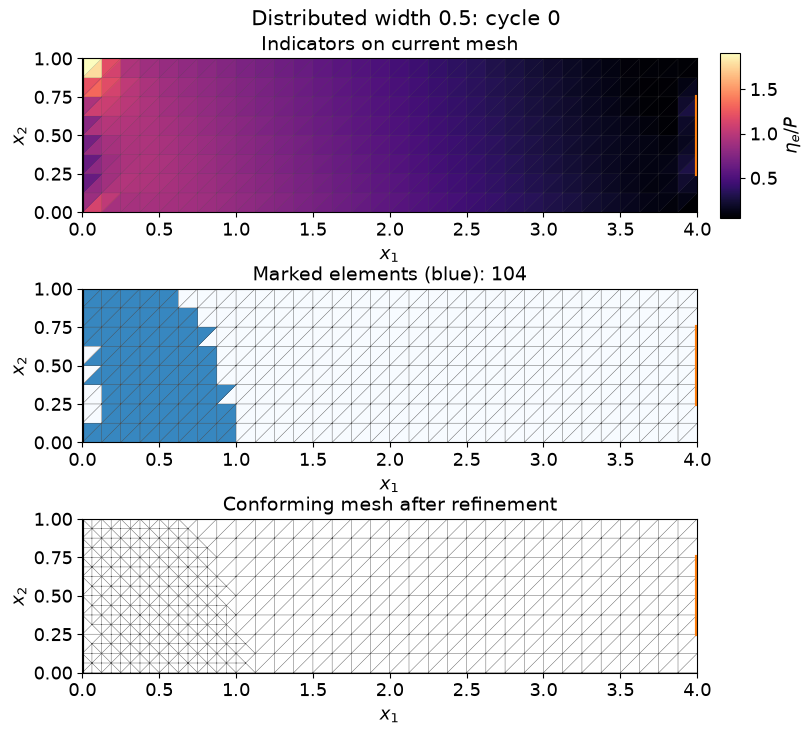

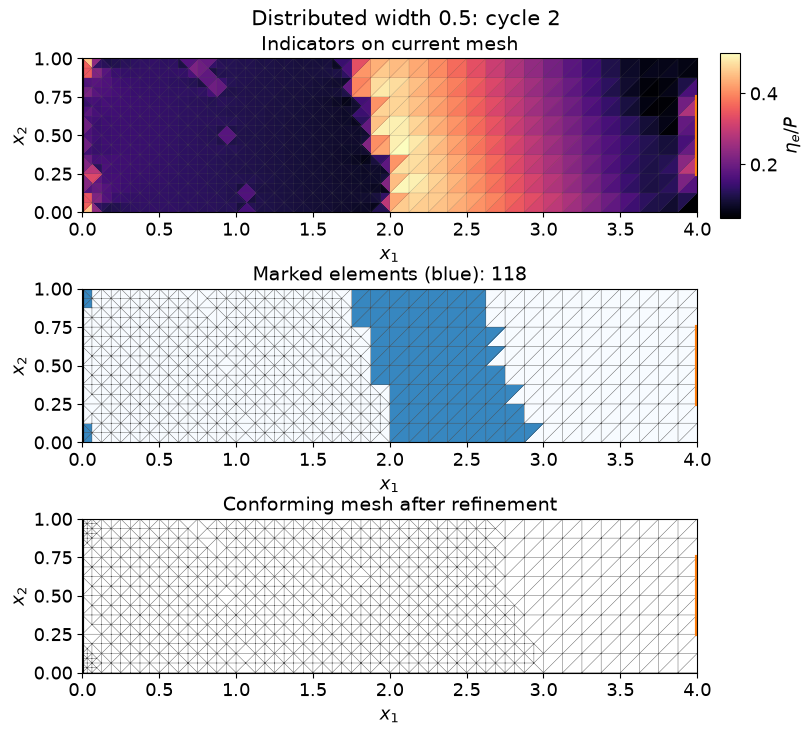

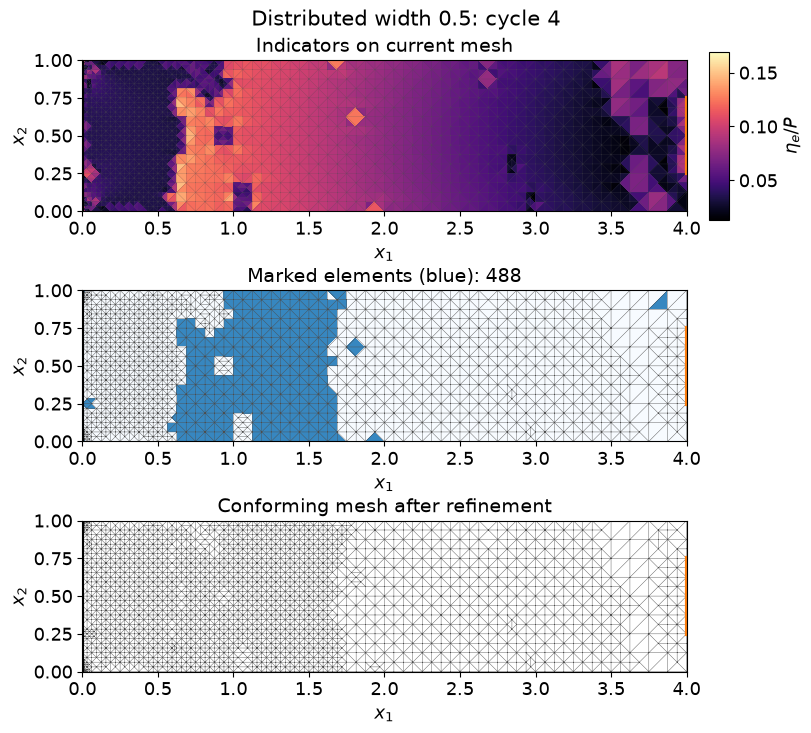

,cycle,DOFs,eta/P,C/P^2,probe displacement/P,marked (next mesh),selected squared fraction
0,0,594,13.763238,253.327009,161.301853,104,0.500967
1,1,960,9.418667,259.953443,166.093416,103,0.502860
2,2,1316,6.475893,263.005119,167.973047,118,0.500107
3,3,1742,4.616700,264.498594,168.651101,378,0.500653
4,4,3116,3.442830,265.668992,169.266420,488,0.500350
5,5,4744,2.665231,266.362267,169.717120,855,0.500135
6,6,7886,2.072848,266.783795,169.913470,0,NaN


/var/folders/tt/zt64sf2n4kgfkx71d8pf39440000gn/T/ipykernel_44746/892400102.py:100: DeprecationWarning: dofmap is deprecated. Use dofmaps[0] instead.
  element_nodes = domain.geometry.x[domain.geometry.dofmap]


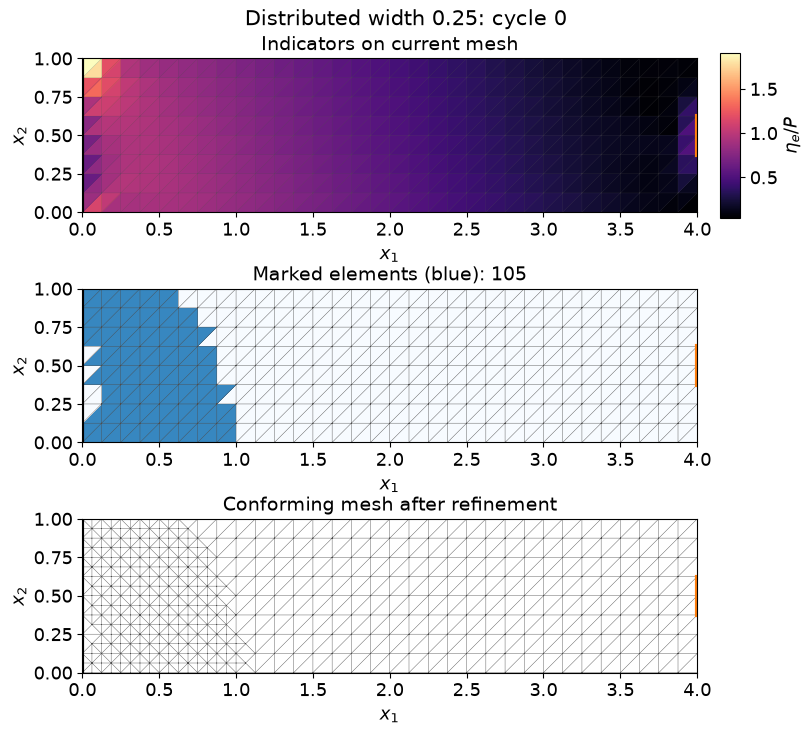

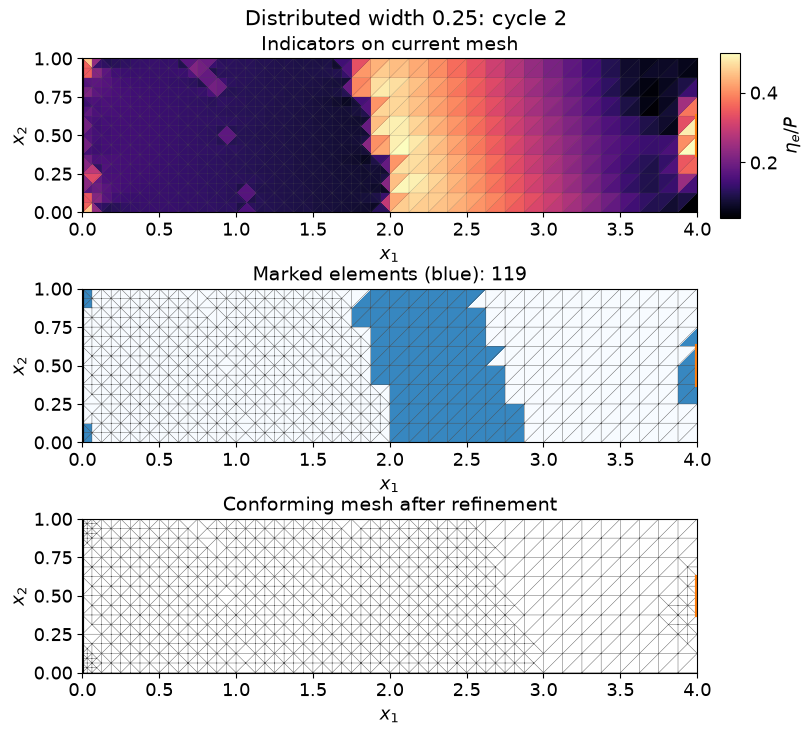

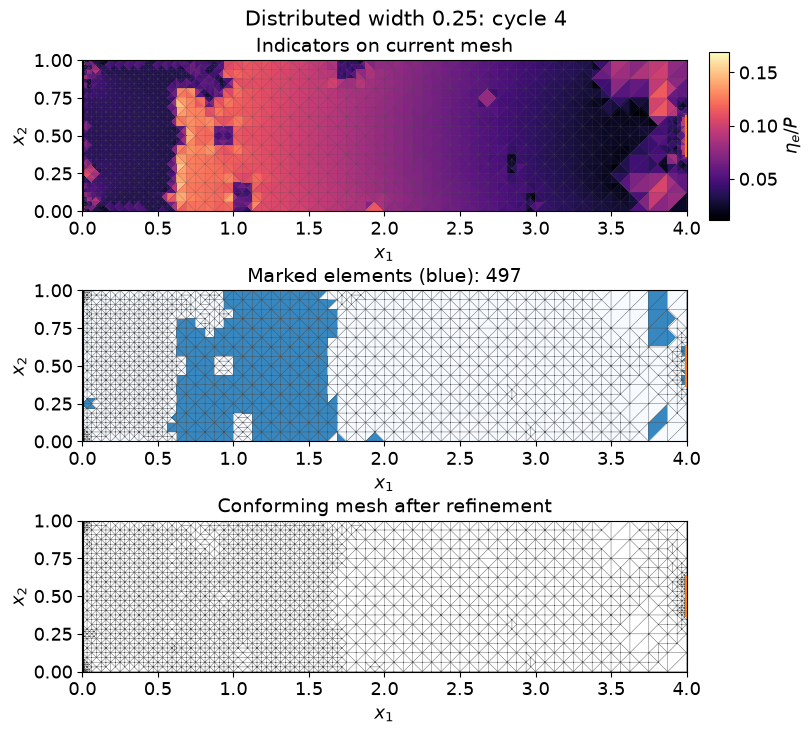

,cycle,DOFs,eta/P,C/P^2,probe displacement/P,marked (next mesh),selected squared fraction
0,0,594,13.795695,253.504427,161.301548,105,0.502146
1,1,960,9.466032,260.130861,166.093111,104,0.501520
2,2,1318,6.544028,263.183892,167.973477,119,0.501375
3,3,1764,4.639888,264.816300,168.647880,381,0.500139
4,4,3178,3.474514,266.021850,169.266719,497,0.500543
5,5,4880,2.681087,266.734272,169.712698,886,0.500219
6,6,8142,2.080509,267.158572,169.914814,0,NaN


In [13]:
for load_width in [0.5, 0.25]:
    adaptive_domain = mesh.create_rectangle(
        MPI.COMM_SELF, [np.array([0., 0.]), np.array([4., 1.])], [32, 8],
        cell_type=mesh.CellType.triangle)
    history = []
    for cycle in range(7):
        result, _, u_adaptive, _ = solve_cantilever(
            8, "distributed", adaptive_domain, width=load_width)
        interior, boundary = estimate_elasticity(adaptive_domain, u_adaptive, load_width)
        squared = interior + boundary
        eta = np.sqrt(squared.sum())
        marked = np.array([], dtype=np.int32)
        fraction = np.nan
        if cycle < 6:
            marked = mark_elements(squared, 0.5)
            fraction = squared[marked].sum()/squared.sum()
            assert fraction >= 0.5
        history.append([cycle, result["DOFs"], eta/P,
                        result["compliance/P^2"], result["probe displacement/P"],
                        len(marked), fraction])
        if cycle < 6:
            refined = refine_marked_elements(adaptive_domain, marked)
            if cycle in [0, 2, 4]:
                draw_elastic_refinement(adaptive_domain, squared, marked, refined,
                                       f"Distributed width {load_width}: cycle {cycle}",
                                       width=load_width)
                plt.show()
            adaptive_domain = refined
    display(pd.DataFrame(history, columns=[
        "cycle", "DOFs", "eta/P", "C/P^2", "probe displacement/P",
        "marked (next mesh)", "selected squared fraction"]))


## Interpretation and limits

The local-refinement study separates the two responses. The point-load successive energy difference divided by $P$ stays close to $0.661$, while the distributed-load difference drops from approximately $0.154$ to $0.00025$. The point-load compliance keeps gaining approximately $0.436P^2$ per local refinement step; the distributed compliance settles within this locally refined family. These are computed observations, not a fitted error estimate.

The uniform study also shows why a displacement measurement away from the load can be misleading if used alone: both models give almost the same displacement at $(3,1/2)$ even though their near-load behavior differs.

Read the computed tables and plots together:

1. Compare the last two compliance increments and successive-mesh energy differences. Do they keep falling for both models, or does the point-load sequence behave differently?
2. Compare that result with the displacement at the fixed probe, one unit away from the load. A displacement away from a singular point can settle even when the global energy does not.
3. Check the near-load density maps. Refining a mesh resolves the loading model that was specified; it does not turn an ideal point force into a force spread over a physical contact region.

The fixed-width traction defines a bounded load functional on the usual elastic energy space. In contrast, ideal point evaluation in this two-dimensional continuum is not bounded in that space. The latter still gives a solvable finite-dimensional problem on each mesh.

These computations are a diagnostic, not a proof of the singular asymptotic behavior. Neither the unknown true error nor an effectivity index is reported. In particular, the standard Chapter 8 residual estimator assumes admissible volume and boundary data; substituting a point force into its ordinary $L^2$ boundary-residual term is not justified.

This example is different from a point load in a **one-dimensional bar or beam theory**, where point evaluation may be continuous in the relevant energy space. Conclusions must be tied to the model.

### Implementation reference

[Dokken's point-source example](https://scientificcomputing.github.io/scifem/examples/point_source.html) shows that a point force contributes a basis-function value to the finite element load vector. Here the force is at an existing $P_1$ node, so that operation is written directly; no additional package is needed. All plots and results above come from this notebook's computations. For further reading on elasticity point sources and alternatives, see [Peng and Vermolen (2019)](https://research.tudelft.nl/en/publications/numerical-methods-to-solve-elasticity-problems-with-point-sources/); their model is not the cantilever problem used here.
